**Aim:** Identify cell types – cluster annotation 

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)

In [1]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300,dpi_save=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

Global seed set to 0


scanpy==1.9.1 anndata==0.8.0 umap==0.5.3 numpy==1.22.4 scipy==1.9.0 pandas==1.4.3 scikit-learn==1.1.2 statsmodels==0.13.2 python-igraph==0.9.11 pynndescent==0.5.7


In [2]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [3]:
# https://stackoverflow.com/questions/3899980/how-to-change-the-font-size-on-a-matplotlib-plot

SMALL_SIZE = 6
MEDIUM_SIZE = 8
BIGGER_SIZE = 10

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


In [4]:
from utils import *

In [5]:
from upsetplot import from_contents, UpSet

## marker genes for neuronal/non-neuronal cells

In [6]:
cell_types = {
    "non-neuronal cells":[
        "Endothelial","Oligodentrocyte",
        # "OPCs", # oligodendrocyte progenitor cells 
        "Microglia","astrocytes",
        # "neuroblast"
        # "interneuron",
    ],

    "neuron":[
        "neuron main markers",
        "GABAergic",
        "glutamatergic",
        "D1 MSN",
        "D2 MSN (Ppp1r1b+ medial spiny neuron)",
        "D1H",
        "ICj"
    ]
}

In [7]:
marker_genes = {
    # "OPCs":['Pdgfra','Olig2'], # oligodendrocyte progenitor cells
    # "interneuron":[
    #     # "Resp18",
    #     # 'Lhx6',
    #     'Zic1'
    # ],
    "Endothelial": ["Cldn5","Ptprb"],
    "Oligodentrocyte":["Mog",'Opalin'], # "Olig1",
    "Microglia":['C1qb','C1qa'], #"Cx3cr1",
    "astrocytes":['Slc1a3','Gja1'], #"Aqp4",
    # "neuroblast":["Top2a"],
    # "neuron main markers":[
    #     # 'Snap25',
    #     'Zic2',#"Gria2", "Penk",'Dck','Nrxn1',"Nfasc","Kctd13",
    #     "Sox11" #"Aplp1","Syt11","Slc2a1","Slc1a2","Slc4a4","Slc6a6","Qpct"
    #                       ],
    "GABAergic":["Gad1"],
    "glutamatergic":[
        "Grin3a",
        "Lrrtm2",
        "Slc1a1",
        "Slc1a2",
        "Gria1",
        # "Gria2",
        # "Grin1",
        # "Slc6a13",
        # "Slc7a11",
        # "Slc17a7",
        # "Slc17a6",
    ],
    "D1 MSN":['Tac1',"Pdyn"], # ,"Drd1a"
    # "D2 MSN":[ # (Ppp1r1b+ medial spiny neuron)
    #     "Penk",
    #     # "Drd2",
    #     "Adora2a"
    # ],
    # "D1H":[
        # "Nxph4",
    #     # "Tac2"
    # ],
    # "ICj":[
    #     # "Crtac1",
    #     "Rreb1"],
    # "patch marker":["Sema5b"],
    # "ventral striatum marker":["Crym"],
    # "medial Shell":[
    #     "Stard5",
    #     "Stra6"]
}

In [8]:
neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type in cell_types['neuron']
}

not_neuron_genes = {
    cell_type: marker_genes[cell_type] 
    # gene 
    for cell_type in marker_genes 
    # for gene in marker_genes[cell_type] 
    if cell_type not in cell_types['neuron']
}

## Load data 
`adata` -> `scvi` denoised and then clustered

In [9]:
results_file = 'preprocessing/adata-denoised-clustered-v2.h5ad.gz'

adata = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.10/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [10]:
del adata.raw, adata.var, adata.uns, adata.varm, adata.obsp

for col in adata.obs.columns[adata.obs.columns.str.startswith('_')]: 
    del adata.obs[col]

In [11]:
adata.var_names_make_unique()

In [12]:
adata

AnnData object with n_obs × n_vars = 21614 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

### Label Neuron

In [13]:
leiden_list = []
for l in adata.obs.leiden_scVI:
    if int(l) in [0,1,2,5,7,12,13,14,15,19,20,21,22,23,24,25]: leiden_list.append('Neuron')
    else: leiden_list.append(l)

adata.obs['label'] = pd.Categorical(leiden_list)

In [16]:
d = pd.DataFrame(adata.obs['label'] == 'Neuron').groupby('label').size()

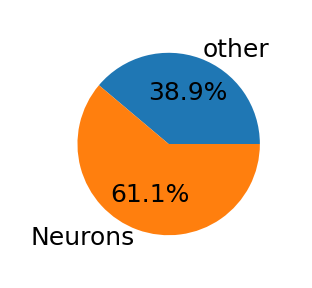

In [17]:
fig = plt.figure(figsize =(1, 1),dpi=150)
plt.pie(d.values,labels=['other','Neurons'],autopct='%1.1f%%')
# show plot
plt.show()

In [18]:
# sc.pl.umap(
#     adata[adata.obs.label == 'Neuron'],
#     color=['Snap25','Sox11',"leiden_scVI"],
#     frameon=False,alpha=0.1,size=30,
#     vmax=1,vmin=0,
#     color_map="Reds",
#     # legend_loc='on data',
#     # add_outline=0.1
# )

## Split dataset

In [19]:
adata_neuron = adata[adata.obs.label == 'Neuron'].copy()

In [20]:
adata_non_neuron = adata[adata.obs.label != 'Neuron'].copy()

# Neurons

### sub-clustering

In [21]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [22]:
adata_neuron

AnnData object with n_obs × n_vars = 13216 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

In [23]:
sc.tl.pca(adata_neuron)

In [24]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_neuron, use_rep="X_scVI")
sc.tl.umap(adata_neuron, min_dist=0.75)

In [25]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_neuron, key_added="leiden_neuron", resolution=0.5)

In [ ]:
sc.pl.umap(
    adata_neuron,
    color=[
        "Gad1", # (GABAergic marker) 
        # "Slc17a6", "Slc17a7", # glutamatergic marker
        "Resp18", # interneuron marker
        "Ppp1r1b",# MSN marker 
        'group',#"leiden_scVI",
        'leiden_neuron'],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    # legend_loc='on data',
    # add_outline=0.1
    save = '_20220912'
)

!mv -v figures/umap_20220912.pdf celltyping/

In [26]:
sc.pl.umap(
    adata_neuron,
    color=['Snap25','Sox11','Grin3a','Apod',#'Gria1',
           'Gt(ROSA)26Sor',
           'group',"leiden_scVI",'leiden_neuron'],
    vmax=1,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=10,
    # legend_loc='on data',
    # add_outline=0.1
)

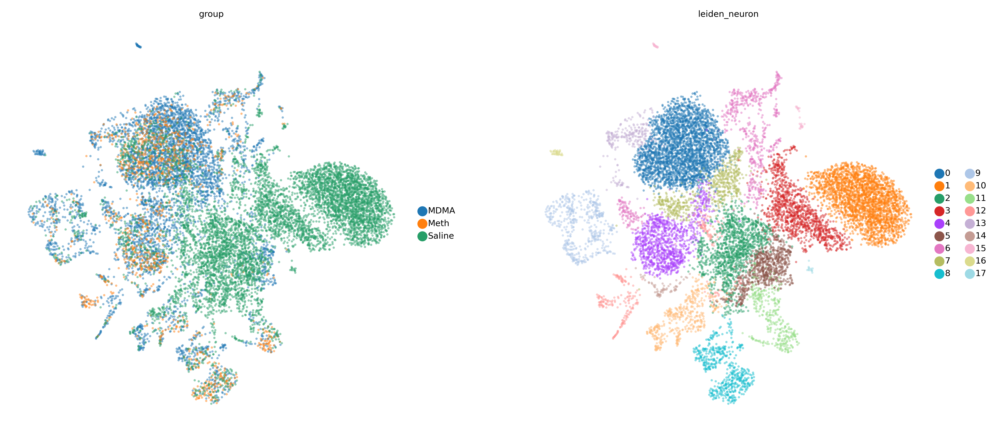

In [28]:
sc.pl.umap(
    adata_neuron,
    color=[
        'group','leiden_neuron'
    ],
    vmin=0,vmax=1,
    color_map="Reds",
    frameon=False,alpha=0.5,size=10,
    # legend_loc='on data',
    # add_outline=0.1
)

### Conditions within sub-clusters

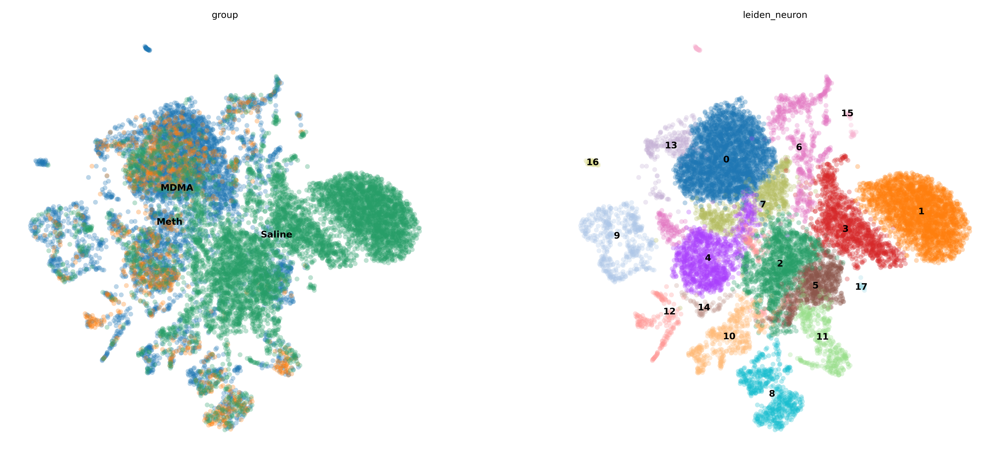

In [33]:
sc.pl.umap(
    adata_neuron,
    color=[
        'group','leiden_neuron'
    ],
    vmin=0,vmax=1,
    color_map="Reds",
    frameon=False,alpha=0.3,size=40,
    legend_loc='on data',
    # add_outline=0.1
)

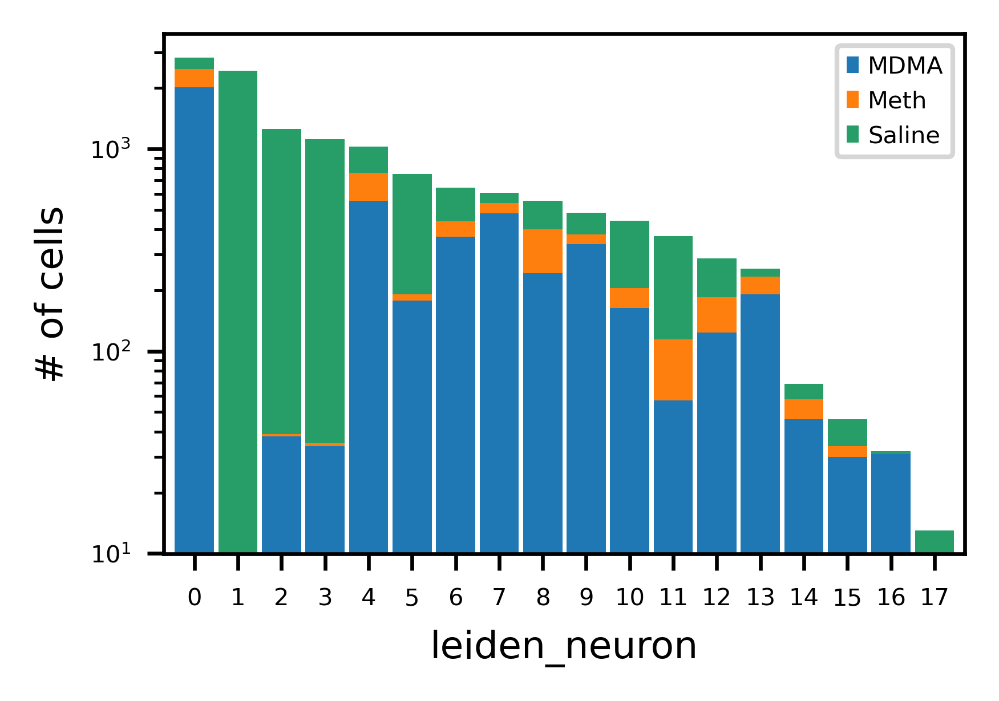

In [29]:
df = pd.DataFrame(adata_neuron.obs.groupby(['group','leiden_neuron']).size()).reset_index().pivot(
    index='group', columns='leiden_neuron', values=0
).T

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('# of cells',fontsize=8)
ax.set_xlabel('leiden_neuron',fontsize=8)
ax.grid(False)
ax.set_yscale('log')

plt.legend(loc='upper right', 
           # bbox_to_anchor=(1.2, 0.5),
           fontsize=5)
plt.show()

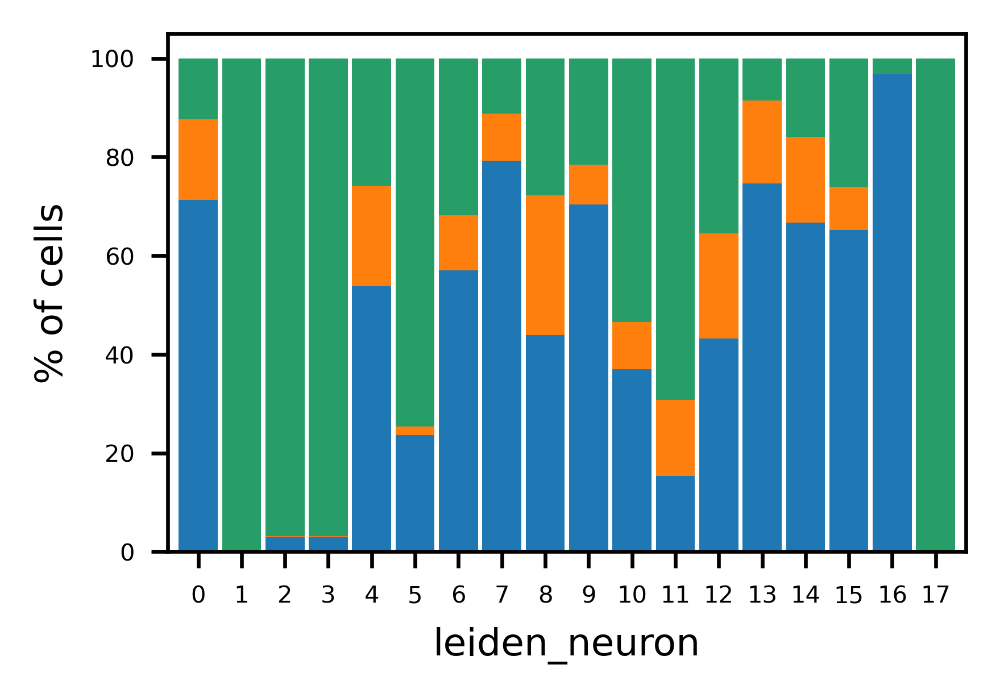

In [30]:
df = pd.DataFrame(adata_neuron.obs.groupby(['group','leiden_neuron']).size()).reset_index().pivot(
    index='group', columns='leiden_neuron', values=0
).T
df = df.div(df.sum(axis=1), axis=0) * 100

ax = df.plot.bar(stacked=True,rot=0,figsize=(3,2),width=0.9,fontsize=5)

ax.patch.set_facecolor('white')
ax.set_ylabel('% of cells',fontsize=8)
ax.set_xlabel('leiden_neuron',fontsize=8)
ax.grid(False)
ax.get_legend().remove()

plt.show()

### Rank genes within sub-clusters

In [36]:
sc.tl.rank_genes_groups(
    adata_neuron, 'leiden_neuron', method='t-test'
)

In [37]:
def revert_upset_dataframe(up_data):
    return up_data.reset_index().set_index('id')

def get_intersection(up_data,which='all'):
    df = revert_upset_dataframe(up_data)
    if which == 'all':
        df = df[df.sum(axis=1) == 1]
        l = list()
        for col in df.columns:
            l.append((col, df.index[df[col]].tolist()))
            
        out = pd.DataFrame(l,columns=['cluster_vs_all','unique_ranked_genes'])
        out.unique_ranked_genes = out.unique_ranked_genes.str.join(',')
            
    else:
        out = pd.DataFrame(
        {
            'cluster_vs_all':which,
            'unique_ranked_genes':[','.join(df.index[df[which.split(',')].sum(axis=1)==2])]
        }
    )

    return out

In [38]:
top_ranked_neuron_clusters_full = rank_genes_to_df(
    adata_neuron, n = 200
)
top_ranked_neuron_clusters = top_ranked_neuron_clusters_full.filter(regex='names')

In [ ]:
upset = UpSet(
    from_contents(top_ranked_neuron_clusters),
    # min_degree=2, 
    subset_size='count',
    min_subset_size=25, 
    show_counts=True,
).plot()

plt.savefig('celltyping/top_ranked_neuron_clusters_largest.pdf',font_size=10)

In [ ]:
upset = UpSet(
    from_contents(top_ranked_neuron_clusters),
    # min_degree=2, 
    subset_size='count',
    # min_subset_size=25, 
    show_counts=True,
).plot()

plt.savefig('celltyping/top_ranked_neuron_clusters_all.pdf',font_size=10)

In [ ]:
top_ranked_neuron_clusters_rev = revert_upset_dataframe(
    from_contents(top_ranked_neuron_clusters)
)

In [ ]:
clusters_unique_ranked_genes = pd.concat([
    get_intersection(from_contents(top_ranked_neuron_clusters)),
    get_intersection(from_contents(top_ranked_neuron_clusters),which='7_names,13_names,0_names'),
    get_intersection(from_contents(top_ranked_neuron_clusters),which='13_names,9_names'),
    get_intersection(from_contents(top_ranked_neuron_clusters),which='0_names,7_names'),
    get_intersection(from_contents(top_ranked_neuron_clusters),which='14_names,4_names'),
    get_intersection(from_contents(top_ranked_neuron_clusters),which='5_names,2_names'),
])

In [ ]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
writer = pd.ExcelWriter('celltyping/top_ranked_neuron_clusters.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
top_ranked_neuron_clusters_full.to_excel(writer, sheet_name='full')
clusters_unique_ranked_genes.set_index('cluster_vs_all').to_excel(writer, sheet_name='clusters_unique_ranked_genes')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

### 
___

In [ ]:
sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [ ]:
adata_neuron

In [ ]:
name = 'top_ranked_neuron_clusters'

ax = sc.pl.dotplot(
    adata_neuron, 
    dict([(clust,genes.split(',')[:10]) for clust,genes in clusters_unique_ranked_genes.values]),
    groupby=['leiden_neuron'], 
    swap_axes=True, 
    dendrogram=True,
    colorbar_title='mean z-score', 
    standard_scale="var",
    vmin=-1, vmax=1, cmap='RdBu_r',
    save = name
)

!mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [ ]:
# name = 'top_ranked_neuron_clusters'

ax = sc.pl.dotplot(
    adata_neuron, 
dict([(clust,genes.split(',')[:5]) for clust,genes in clusters_unique_ranked_genes.values
      if clust in ['5_names,2_names','14_names,4_names']]),
    groupby=['leiden_neuron'],
    swap_axes=True, 
    dendrogram=True,
    colorbar_title='mean z-score', 
    standard_scale="var",
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = name
)

# !mv -v figures/dotplot_{name}.pdf celltyping/{name}_dotplot.pdf

In [ ]:
# sc.tl.dendrogram(adata_neuron,'leiden_neuron')

In [ ]:
# ax = sc.pl.dotplot(
#     adata_neuron, 
#     [gene for clust,genes in temp for gene in genes],# if clust in ['8_names','5_names','0_names',
#                                                                     # '1_names','2_names','4_names']], 
#     groupby=['leiden_neuron'], 
#     swap_axes=False, 
#     dendrogram=True,
#     colorbar_title='mean z-score', 
#     # layer='scaled', 
#     vmin=-4, vmax=4, cmap='RdBu_r',
#     # save = 'Snap25_neg'
# )

# # !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

### Save to file

Here, we need to think more about how to find subclusters!

In [ ]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron.write_h5ad(results_file)

### Sub cluster Marker genes 

In [6]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = sc.read_h5ad(results_file)

In [7]:
adata_neuron

AnnData object with n_obs × n_vars = 13216 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'TdT label', 'Sox11 label', 'label', 'leiden_neuron'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'dendrogram_leiden_neuron', 'group_colors', 'hvg', 'leiden', 'leiden_neuron_colors', 'leiden_scVI_colors', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    varm: 'PCs'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

In [29]:
new_markers = {
    "Synaptic cell adhesion/transmission":[
        "Nrxn1", "Nrxn2", "Nrxn3", "Lrrtm2", "Nlgn3","Nxph1", "Ncam1",'Ncam2', 'Homer2', 'Syt11',
        'Gria3', 'Gria4', 'Grin2c', 'Camk2d'
    ],
    "Cell type markers": [
        "Gad1", "Gad2", "Pcp4l1", "Sox11",
    ],
    "Solute carriers": [
        "Slc6a6", "Slc38a11", "Slc6a11",
    ],
    "Neuromodulator receptor": [
        "Drd1", "Drd2", "Penk", "Tac1", "Htr2c", "Adora1", 
        "Npy1r", "Opcml", "Ntsr2", "Ntrk2",
    ],
    "Neurotrophic": [
        "Epha5", "Ndnf", "Ntn4", "Sema7a", "Nnat",
    ]
    }

# new_markers = [
#     # 0: 
#     'Adora1', 'Lrrtm2', 'Ncam1', 'Ncam2', 'Nlgn3', 'Nrxn1', 'Nrxn2', 'Nxph1', 'Syt11',
#     # 2:
#     "Sema7a", "Ndnf","Pcp4l1", #(Pukinje cell)
#     # 3:
#     "Slc6a6", #(Chloride)
#     # 4:
#     "Nrxn1","Nrxn2","Grid2","Gria2","Opcml",
#     # 5:
#     "Sema7a",
#     # 6:
#     "Ncam2","Cadm1","Homer2", "Ncam1", "Itpr2", #(in neuron and astrocytes)
#     # 7:
#     "Nrxn1","Epha5","Nxph1","Gria3","Grid2","Ncam2",
#     # 9:
#     "Nrxn3","Sox11","Nnat","Gad2",
#     # 10:
#     "Ntn4","Npy1r","Slc38a11",
#     # 12:
#     "Nrxn3","Gria2","Gad2","Tac1","Htr2c","Penk","Gad1","Drd1",
#     # 13:
#     "Cntn1","Ntrk2","Nxph1","Nrxn1","Gria3","Syt11","Nlgn3","Gria4",
#     # 14:
#     "Grin2c","Camk2d","Ntsr2","Ntrk2",
#     # 15:
#     "Penk",
#     # 16:
#     "Drd2","Drd1",
#     # 17:
#     "Ntsr2","Slc6a11"
# ]

categories: 0, 1, 2, etc.
var_group_labels: Synaptic cell adhesion/transmission, Cell type markers, Solute carriers, etc.


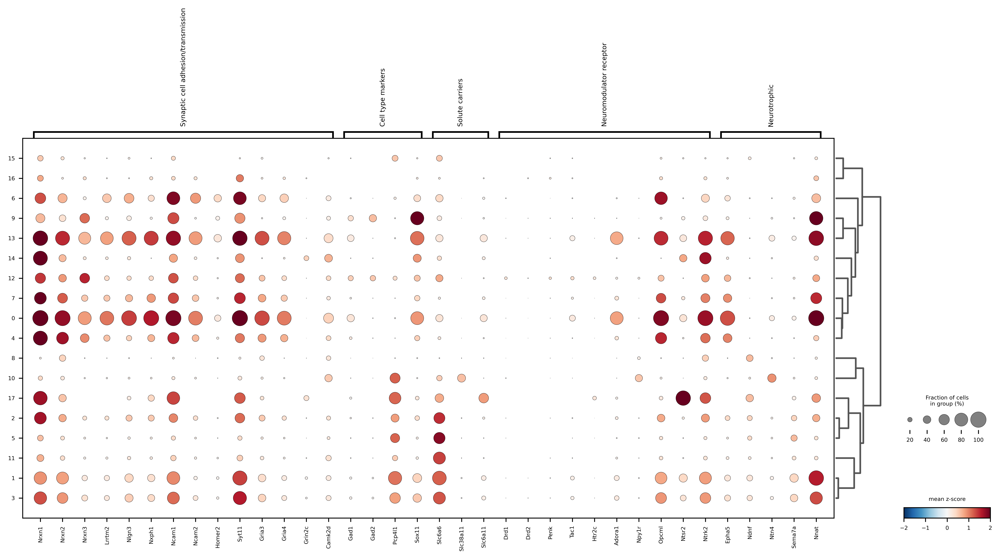

‘figures/dotplot_neuron_new_markers.pdf’ -> ‘celltyping/neuron_new_markers_dotplot_v2.pdf’


In [32]:
ax = sc.pl.dotplot(
    adata_neuron,
    new_markers, 
    groupby=['leiden_neuron'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    # layer='scaled', 
    vmin=-2, vmax=2, cmap='RdBu_r',
    save = 'neuron_new_markers'
)

!mv -v figures/dotplot_neuron_new_markers.pdf celltyping/neuron_new_markers_dotplot_v2.pdf

### rank_genes_groups_dotplot

In [ ]:
ax = sc.pl.rank_genes_groups_dotplot(
    adata_neuron, 
    groupby=['leiden_neuron'],
    n_genes=5,
    values_to_plot='logfoldchanges', min_logfoldchange=3,
    vmin=-4, vmax=4, cmap='RdBu_r',
)

In [ ]:
ax = sc.pl.rank_genes_groups_dotplot(
    adata_neuron, 
    groupby=['leiden_neuron'],
    n_genes=10,
    values_to_plot='logfoldchanges', min_logfoldchange=3,
    groups=['3','4'],
    vmin=-4, vmax=4, cmap='RdBu_r',
)

# Non-Neurons

In [66]:
adata_non_neuron

AnnData object with n_obs × n_vars = 8398 × 10013
    obs: 'batch', 'cond', 'group', 'leiden_scVI', 'Snap25 label', 'Apod label', 'TdT label', 'Sox11 label', 'label'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'scvi_normalized'

In [67]:
# The result of the previous highly-variable-genes detection is stored as 
# an annotation in .var.highly_variable and auto-detected by PCA and hence, 
# sc.pp.neighbors and subsequent manifold/graph tools. 
# In that case, the step actually do the filtering below is unnecessary, too.

sc.pp.highly_variable_genes(
    adata_non_neuron, min_mean=0.0125, max_mean=3, min_disp=0.5,
)

In [68]:
sc.tl.pca(adata_non_neuron)

In [69]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata_non_neuron, use_rep="X_scVI")
sc.tl.umap(adata_non_neuron, min_dist=0.3)

In [70]:
# neighbors were already computed using scVI
sc.tl.leiden(adata_non_neuron, key_added="leiden_non_neuron", resolution=0.3)

In [71]:
sc.tl.dendrogram(adata_non_neuron,'leiden_non_neuron') 

In [ ]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['leiden_non_neuron'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    # layer='scaled', 
    vmin=-1, vmax=1, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

In [72]:
leiden_list = []
for l in adata_non_neuron.obs.leiden_non_neuron:
    if int(l) in [5,6,8,9]: leiden_list.append('Microglia')
    elif int(l) in [7]: leiden_list.append('Astrocytes')
    elif int(l) in [1,3]: leiden_list.append('Endothelial')
    elif int(l) in [0,2,4]: leiden_list.append('Oligodendrocytes')
    else: leiden_list.append(l)

adata_non_neuron.obs['label'] = pd.Categorical(leiden_list)

In [73]:
sc.tl.dendrogram(adata_non_neuron,'label') 

categories: Astrocytes, Endothelial, Microglia, etc.
var_group_labels: Endothelial, Oligodentrocyte, Microglia, etc.


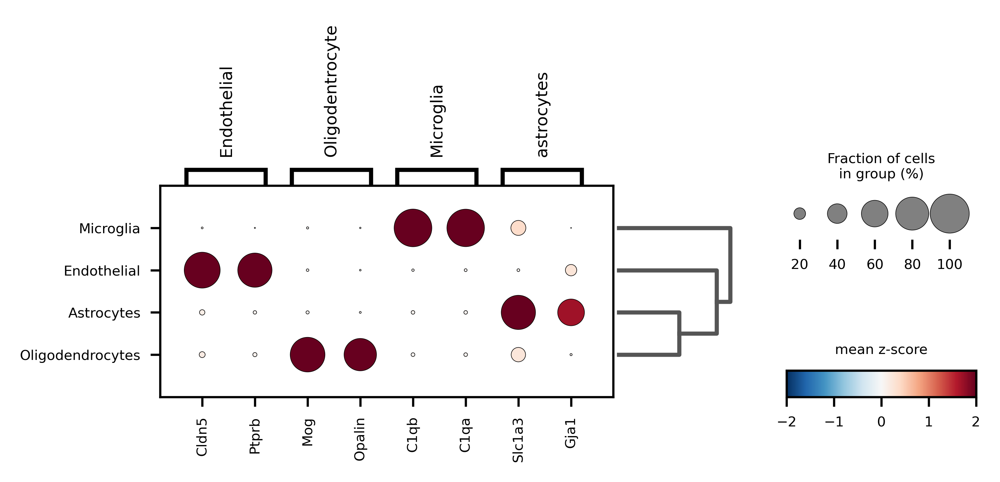

In [78]:
ax = sc.pl.dotplot(
    adata_non_neuron,
    not_neuron_genes, 
    groupby=['label'], 
    swap_axes=False, dendrogram=True,
    colorbar_title='mean z-score', 
    # layer='scaled', 
    vmin=-2, vmax=2, cmap='RdBu_r',
    # save = 'Snap25_neg'
)

# !mv -v figures/dotplot_Snap25_neg.pdf celltyping/Snap25_neg_dotplot.pdf

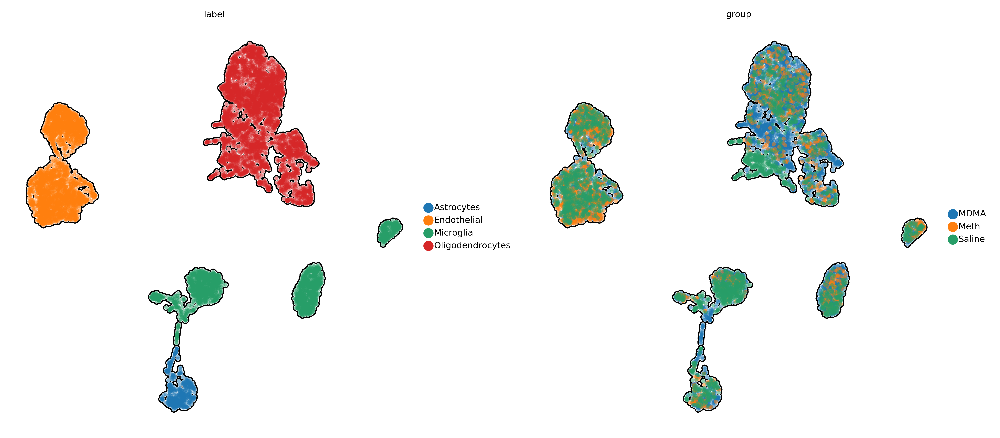

In [79]:
sc.pl.umap(
    adata_non_neuron,
    color=[
        'label',
        # 'leiden_scVI',
        # 'leiden_non_neuron',
        # "Mog","Ptprb",
        # "Snap25",'Sox11',
        'group',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=30,
    # legend_loc='on data',
    add_outline=0.1
)

In [80]:
sc.tl.rank_genes_groups(adata_non_neuron, 'label', 
                        n_genes=adata_non_neuron.shape[1], method='t-test'
                       )

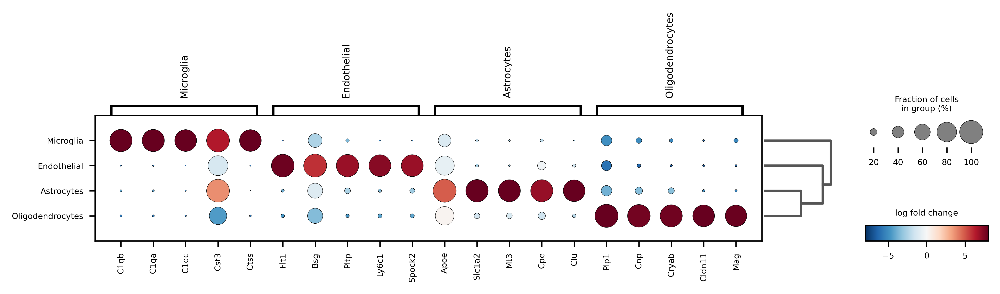

In [81]:
ax = sc.pl.rank_genes_groups_dotplot(
    adata_non_neuron, 
    # groupby=['label'],
    n_genes=5,
    values_to_plot='logfoldchanges', min_logfoldchange=3,
    # groups=['12','10','6','9'],
    vmin=-8, vmax=8, cmap='RdBu_r',
)

In [83]:
non_neuron_ranks = rank_genes_to_df(adata_non_neuron, n = 50)
# non_neuron_ranks
# Snap25_pos_rankdf.to_csv('celltyping/Snap25_pos_rank_genes.csv',index=False)

In [85]:
# non_neuron_ranks

##### 
save :)

In [82]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron.write_h5ad(results_file)

# All data

In [86]:
adata.obs['final label'] = ''

adata.obs.loc[adata_neuron.obs_names,'final label'] = "neuron"#list(adata_neuron.obs.leiden_neuron)
adata.obs.loc[adata_non_neuron.obs_names,'final label'] = list(adata_non_neuron.obs.label)

adata.obs['final label'] = pd.Categorical(adata.obs['final label'])

In [87]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata, min_dist=0.3)

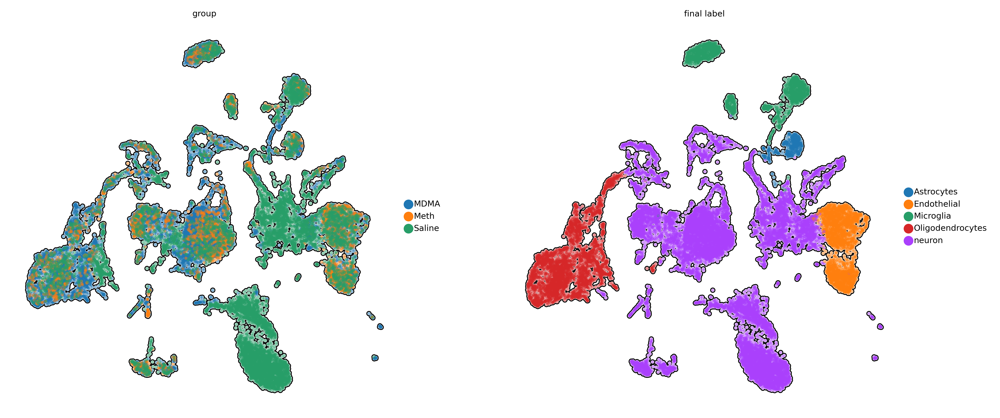

In [90]:
sc.pl.umap(
    adata,
    color=[
        'group',
        # 'leiden_scVI',
        'final label',
        # "Sox11",'Snap25',
    ],
    vmax=2,
    vmin=0,
    color_map="Reds",
    frameon=False,alpha=0.5,size=20,
    # legend_loc='on data',
    add_outline=0.1
)

# 

In [100]:
!date

Wed Aug 24 19:02:46 PDT 2022
